In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [28]:
df=pd.read_csv("DataSets/Salary_Data.csv")

In [29]:
#TO GET A WORKING HYPOTHESIS YHAT OR H(THETA) WE NEED TO START AT SOME POINT IN Y=MX+B 

diffrence_in_Yhat_Y=0
weight=0
bias=0
learningrate=0.05
 #DATA PREPROCESSING STEP
#80/20 split in x and y random shuffling is done before because x,y might gets lost if random shuffling applied to x and y independently as our x and y has been seperated already
random_indexes=np.random.permutation(len(X)) #generating random indexes [1,5,3,7,11,2,...]

X,Y=X[random_indexes],Y[random_indexes] #Sorting dataset according to same random indexes that comes from above variable random_indexes

split_index=int(0.8*len(X)) #if dataset contains n no of data indexes find where 80 % lies take floor value 


#80/20 SPLIT 
X_train,X_test=np.array(X[:split_index]),np.array(X[split_index:]) #now split them accordingy [:Split_index] gives first 80% of data as train [split_index:] gives rest 20% testing
Y_train,Y_test=np.array(Y[:split_index]),np.array(Y[split_index:])

#NORMALIZATION OF TRAINING DATA  because it will reduce chances of overflow basically scaling down
X_mean,X_std=X_train.mean(),X_train.std()  #calculating mean and standard deviations
Y_mean,Y_std=Y_train.mean(),Y_train.std()

X_train = (X_train - X_mean) / X_std #(orginal_train_data-avg_of_dataset)/standard deviation)
Y_train = (Y_train - Y_mean) / Y_std  

n=int(len(X_train)) # this gives no of training examples
# diffY_times_x_train

def Yhat(w,b,x): #calculates Y also called Yhat or hypothesis
    return w*x+b




cost_history=np.array([])
weight_history=np.array([])
bias_history=np.array([])

#TRANING THE MODEL

for iterations in range(10000): 
    #INITIALIZATION OF Ypred-ActualY as numpy array for n no of traning examples
    diffY=np.array([])
    #initialization of diffrence in ypred and actualY times ith X to calculate weight later
    diffY_times_x_train=np.array([]) 
 
    #for every ith data in training data calculate diff in actual and predicted Y also calculate weight from each example as shown in variable diffY_times_x_train
    for i in range(0,len(X_train)):
        diffY=np.append(diffY,(Yhat(weight,bias,X_train[i])-Y_train[i]))
        diffY_times_x_train=np.append(diffY_times_x_train,diffY[i]*X_train[i])
        
    weight_history=np.append(weight_history,weight)
    bias_history=np.append(bias_history,bias)
    # update the weight as shown below after iterating over every training examples as shown above which used old weight    
    weight -= ((learningrate)/n)*np.sum(diffY_times_x_train)
    bias -=(learningrate/n)*np.sum(diffY)
    # calculate the error square as shown below  and exit loop if error is <=0.1
    error=(1/n)*np.sum(np.array(diffY**2))
    cost_history=np.append(cost_history,error)
    if error<=0.1:
        break
        
    
#initialize the tested data array to test wether latest updated bias and weight work
tested_data=np.array([])
#since training data was only normalized and learning model works for normalized data normalizing testing data
normalized_test_data=(X_test-X_mean)/X_std #test data normalization

#now with help of normalized test data and calculated weight and bias we get normalized y predictions
normalized_predicted_data = Yhat(weight, bias, normalized_test_data) 
#normalizing test Y to evaluate with normalized Y predictions
normalized_test_Y=(Y_test-Y_mean)/Y_std

print(error)


#SINCE WEIGHT AND BIAS ARE IN NORMALIZED FORM WE DE NORMALIZE IT TO PLOT AGAINST ORGINAL X AND Y
weight=weight*(Y_mean/X_mean) #denormalization of weight
bias=Y_mean+(Y_std*bias)-(weight*X_mean) #denormalization of bias
print(normalized_predicted_data-normalized_test_Y)


    

0.099092205793879
[-0.42925319  0.37530815 -0.2055622   0.16723209 -0.34720323 -0.71464048]


Text(0, 0.5, 'salary')

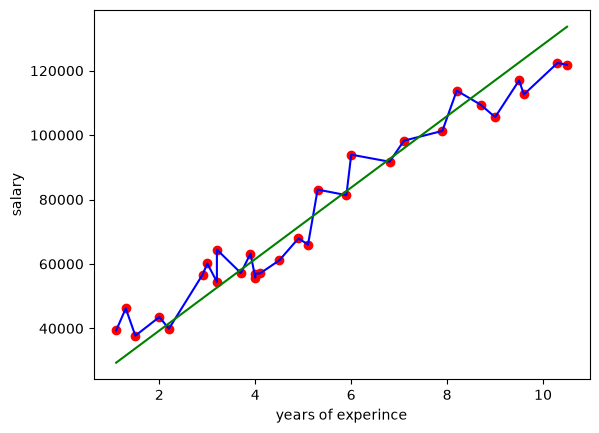

In [30]:
#model visualization
X= np.array(df["YearsExperience"])
Y=np.array(df["Salary"])
y_line=weight*X+bias
plt.scatter(X,Y,c="r",label="original dataset")
plt.plot(X,Y,c="b")
plt.plot(X,y_line,c="g")
plt.xlabel("years of experince")
plt.ylabel("salary")


RedScatter:Original DataPoints-------
Bluelines:Original DataPoints plotting ---------
Green:RegressionLine or SLR Model ----- 

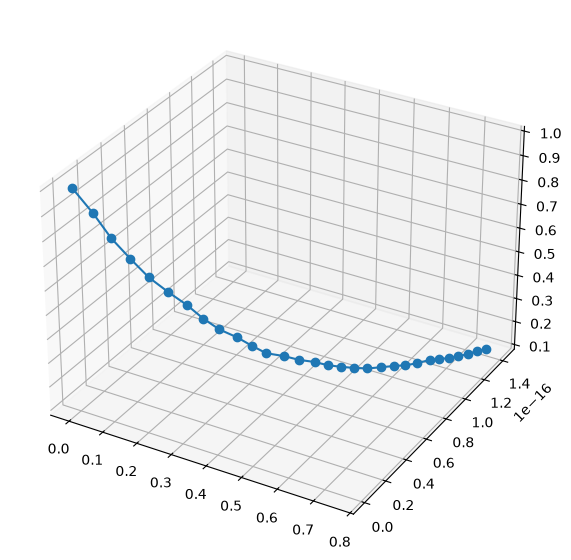

In [31]:
#visualization of gradient descend

fig=plt.figure(figsize=(10,7))
axis=fig.add_subplot(111,projection='3d')
axis.plot(
    weight_history,
    bias_history,
    cost_history,
    marker='o')
plt.show()